# Homework Part B — Classification: Diabetes Diagnosis

**Student:** Varshith Reddy

**Task.** Predict whether a patient has diabetes (Pima Indians Diabetes data, 768 women aged 21 or older) from 8 clinical measurements.

**Approach.** Same class workflow as Part A:
* a utility object holds settings and helpers;
* preprocessing lives inside the PyTorch model, including the imputation of impossible zero readings;
* training uses Adam (lr = 0.001), batch size 16 and fixed epochs;
* models are compared with 5-fold stratified cross-validation, and the 20 % test set is used once;
* the selected model is exported to ONNX (`input1` / `output1`) for GitHub Pages.

**Metrics:** F-measure (F1) for the diabetic class, precision, recall, accuracy, specificity, ROC-AUC, the confusion matrix and the feature correlation matrix.

In [1]:
## Colab already has torch, pandas, sklearn and matplotlib. Uncomment if needed:
## !pip install onnx onnxruntime mlxtend

In [2]:
import os, json, copy, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score, roc_auc_score,
                             confusion_matrix, classification_report, roc_curve)
from mlxtend.plotting import heatmap
import onnxruntime as rt

np.set_printoptions(suppress=True)
torch.set_printoptions(sci_mode=False)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
os.makedirs('figures', exist_ok=True)
os.makedirs('ONNXmodels', exist_ok=True)
print(torch.__version__, device)

2.14.1 cpu


## 1. Utility object

In [3]:
class ClassificationUtils:

    def __init__(self):
        self.random_seed   = 42
        self.test_size     = 0.20
        self.n_folds       = 5
        self.batch_size    = 16
        self.learning_rate = 0.001
        self.N_EPOCHS      = 150
        self.epsilon       = 0.0001

    def set_seed(self):
        random.seed(self.random_seed); np.random.seed(self.random_seed); torch.manual_seed(self.random_seed)

    def read_csv_file_with_pandas(self, url, names):
        self.df = pd.read_csv(url, header=None, names=names)
        return self.df

    def split_np_data_train_test(self, X, y):
        self.X_train, self.X_test, self.y_train, self.y_test = train_test_split(
            X, y, test_size=self.test_size, random_state=self.random_seed, stratify=y)

    def imputation_and_scaling_stats(self, X):
        ## medians of the NON-zero readings, then means / deviations after imputation (training rows only)
        X = X.copy()
        medians = np.zeros((1, X.shape[1]), dtype=np.float32)
        for j in ZERO_MEANS_MISSING_IDX:
            col = X[:, j]
            medians[0, j] = np.median(col[col > 0])
            col[col == 0] = medians[0, j]
        X_t = torch.tensor(X, dtype=torch.float32)
        return (torch.tensor(medians), X_t.mean(0, keepdim=True), X_t.std(0, keepdim=True) + self.epsilon)

    def gen_Dataloader_train(self, X, y):
        ds = TensorDataset(torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.float32).view(-1, 1))
        return DataLoader(ds, self.batch_size, shuffle=True, drop_last=True)

U = ClassificationUtils()

## 2. Read the data

In [4]:
URL = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv'
FEATURES = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI',
            'DiabetesPedigreeFunction', 'Age']
df = U.read_csv_file_with_pandas(URL, names=FEATURES + ['Outcome'])
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


## 3. Exploratory analysis

Zero readings (physiologically impossible, i.e. missing):
               zeros  percent
Glucose            5      0.7
BloodPressure     35      4.6
SkinThickness    227     29.6
Insulin          374     48.7
BMI               11      1.4

Class balance:
Outcome
0    500
1    268
Name: count, dtype: int64


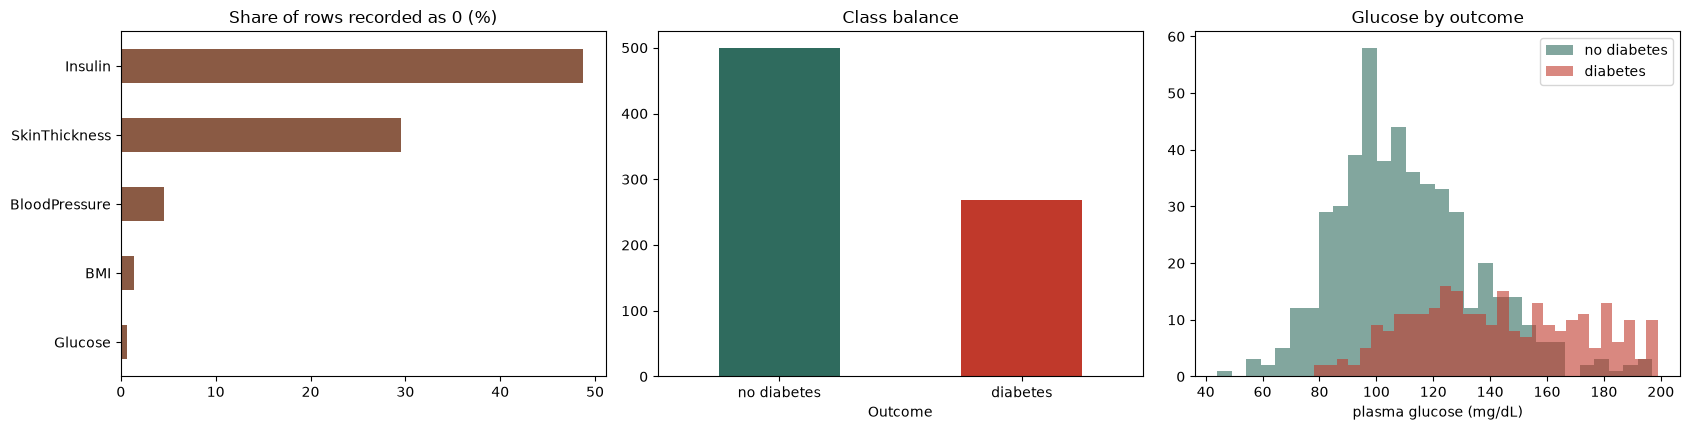

In [6]:
ZERO_MEANS_MISSING = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
ZERO_MEANS_MISSING_IDX = [FEATURES.index(c) for c in ZERO_MEANS_MISSING]
zeros = (df[ZERO_MEANS_MISSING] == 0).sum()
print('Zero readings (physiologically impossible, i.e. missing):')
print(pd.DataFrame({'zeros': zeros, 'percent': (100 * zeros / len(df)).round(1)}))
print('\nClass balance:'); print(df.Outcome.value_counts())

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
(100 * zeros / len(df)).sort_values().plot.barh(ax=axes[0], color='#8A5A44')
axes[0].set_title('Share of rows recorded as 0 (%)')
df.Outcome.map({0: 'no diabetes', 1: 'diabetes'}).value_counts().plot.bar(ax=axes[1], color=['#2F6B5E', '#C0392B'])
axes[1].set_title('Class balance'); axes[1].tick_params(axis='x', rotation=0)
for lab, c in [(0, '#2F6B5E'), (1, '#C0392B')]:
    g = df.loc[(df.Outcome == lab) & (df.Glucose > 0), 'Glucose']
    axes[2].hist(g, bins=30, alpha=0.6, color=c, label='diabetes' if lab else 'no diabetes')
axes[2].set_title('Glucose by outcome'); axes[2].set_xlabel('plasma glucose (mg/dL)'); axes[2].legend()
plt.tight_layout(); plt.savefig('figures/B_eda.png', dpi=130); plt.show()

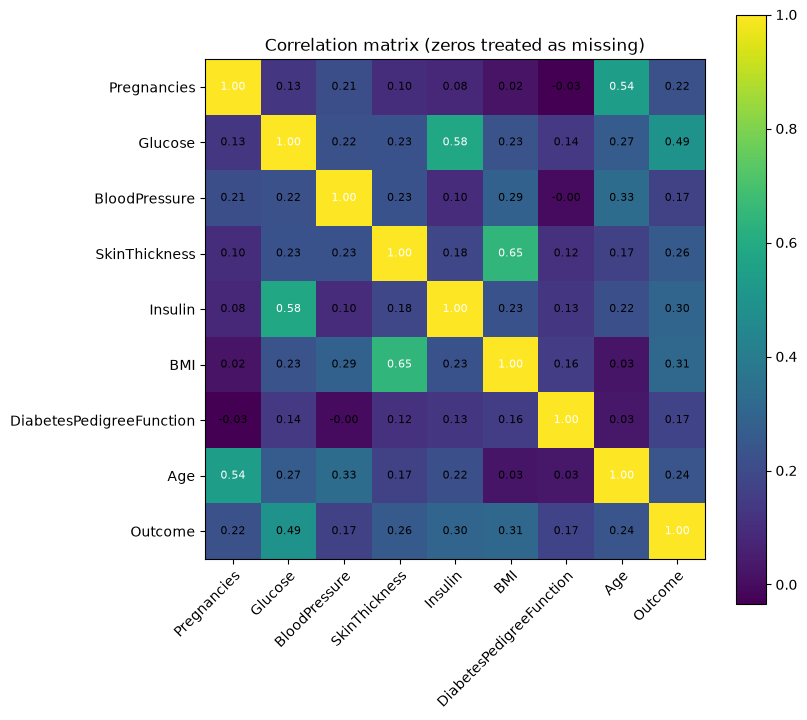

Glucose                     0.494650
BMI                         0.313680
Insulin                     0.303454
SkinThickness               0.259491
Age                         0.238356
Pregnancies                 0.221898
DiabetesPedigreeFunction    0.173844
BloodPressure               0.170589
Name: Outcome, dtype: float64

In [7]:
## correlation matrix, with the impossible zeros treated as missing (pairwise correlations)
df_nan = df.copy()
df_nan[ZERO_MEANS_MISSING] = df_nan[ZERO_MEANS_MISSING].replace(0, np.nan)
corr = df_nan.corr().values
cols = FEATURES + ['Outcome']
fig, ax = heatmap(corr, row_names=cols, column_names=cols, figsize=(8.5, 7.5), cell_font_size=8)
plt.title('Correlation matrix (zeros treated as missing)')
plt.tight_layout(); plt.savefig('figures/B_corr.png', dpi=130); plt.show()
df_nan.corr()['Outcome'].drop('Outcome').sort_values(ascending=False)

**Observations**
* 35 % of patients are diabetic, so the classes are moderately imbalanced. F1 for the diabetic class is the main metric.
* Five columns use 0 for "not measured". Insulin is missing in 49 % of rows and skin thickness in 30 %.
* Glucose is the strongest single signal (r = 0.50), followed by BMI (0.31), insulin (0.30) and skin thickness (0.26). Insulin overlaps with glucose (r = 0.58) and skin thickness with BMI (r = 0.65), so they add little once glucose and BMI are known.

## 4. Preprocessing

* Stratified 80 / 20 split, so both sets keep the 35 % diabetic rate.
* Inside the model, a 0 in one of the five "missing" columns is replaced by the training median of that column's non-zero values (`torch.where`). The web page can therefore accept 0 as "unknown".
* All 8 features are then standardized with training statistics stored as model buffers.

In [8]:
X = df[FEATURES].values.astype(np.float32)
y = df['Outcome'].values.astype(np.float32)
U.split_np_data_train_test(X, y)
N_IN = len(FEATURES)
ZERO_MASK = torch.zeros(1, N_IN)
ZERO_MASK[0, ZERO_MEANS_MISSING_IDX] = 1.0
print('train', U.X_train.shape, f'diabetic {U.y_train.mean():.3f} | test', U.X_test.shape, f'diabetic {U.y_test.mean():.3f}')

train (614, 8) diabetic 0.349 | test (154, 8) diabetic 0.351


## 5. Models

A `ClfPipeline` wraps each core network. It imputes the missing zeros, standardizes the inputs and returns **one logit**. Training uses `BCEWithLogitsLoss` with `pos_weight = negatives / positives`, so a missed diabetic patient costs more than a false alarm.

| Core | Description |
|---|---|
| `LogisticReg` | one `nn.Linear(8, 1)` layer (logistic regression) |
| `ShallowTanh` | 8 → 32 (Tanh) → 1 |
| `F1plusF2` | class model: linear F1 + nonlinear F2 (10 sigmoid units, dropout 0.25) |
| `ResidualNet` | class model: two 64-unit ReLU layers with a projected skip connection |
| `DeepBN` | 8 → 64 → 64 → 32 → 1 with batch normalization |

In [9]:
class ClfPipeline(nn.Module):
    def __init__(self, core, medians, x_means, x_deviations):
        super().__init__()
        self.core = core
        self.register_buffer('medians', medians.clone())
        self.register_buffer('zero_mask', ZERO_MASK.clone())
        self.register_buffer('x_means', x_means.clone())
        self.register_buffer('x_deviations', x_deviations.clone())

    def forward(self, x):
        missing = (x == 0) & (self.zero_mask > 0)
        x = torch.where(missing, self.medians.expand_as(x), x)
        z = (x - self.x_means) / self.x_deviations
        return self.core(z)                     ## logit [N, 1]


class LogisticReg(nn.Module):
    def __init__(self, n_in):
        super().__init__(); self.linear1 = nn.Linear(n_in, 1)
    def forward(self, z):
        return self.linear1(z)


class ShallowTanh(nn.Module):
    def __init__(self, n_in, hidden=32):
        super().__init__()
        self.fc1, self.act1, self.fc2 = nn.Linear(n_in, hidden), nn.Tanh(), nn.Linear(hidden, 1)
    def forward(self, z):
        return self.fc2(self.act1(self.fc1(z)))


class F1plusF2(nn.Module):
    def __init__(self, n_in):
        super().__init__()
        self.f1_linear1 = nn.Linear(n_in, 1)
        self.f2_linear1 = nn.Linear(n_in, 10)
        self.f2_act1    = nn.Sigmoid()
        self.f2_dropout = nn.Dropout(0.25)
        self.f2_linear2 = nn.Linear(10, 1)
    def forward(self, z):
        return self.f1_linear1(z) + self.f2_linear2(self.f2_dropout(self.f2_act1(self.f2_linear1(z))))


class ResidualNet(nn.Module):
    def __init__(self, n_in, hidden=64, dropout_rate=0.1):
        super().__init__()
        self.fc1 = nn.Linear(n_in, hidden);   self.act1 = nn.ReLU(); self.dropout1 = nn.Dropout(dropout_rate)
        self.fc2 = nn.Linear(hidden, hidden); self.act2 = nn.ReLU(); self.dropout2 = nn.Dropout(dropout_rate)
        self.fc3 = nn.Linear(hidden, 1)
        self.input_proj = nn.Linear(n_in, hidden)
    def forward(self, z):
        x0 = self.input_proj(z)
        x1 = self.dropout1(self.act1(self.fc1(z)))
        x2 = self.dropout2(self.act2(self.fc2(x1)))
        return self.fc3(x2 + x0)


class DeepBN(nn.Module):
    def __init__(self, n_in):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_in, 64), nn.BatchNorm1d(64), nn.ReLU(),
            nn.Linear(64, 64),   nn.BatchNorm1d(64), nn.ReLU(),
            nn.Linear(64, 32),   nn.ReLU(),
            nn.Linear(32, 1))
    def forward(self, z):
        return self.net(z)


CORES = {'LogisticReg': LogisticReg, 'ShallowTanh': ShallowTanh, 'F1plusF2': F1plusF2,
         'ResidualNet': ResidualNet, 'DeepBN': DeepBN}
for name, C in CORES.items():
    print(f'{name:12s}', sum(p.numel() for p in C(N_IN).parameters()), 'parameters')

LogisticReg  9 parameters
ShallowTanh  321 parameters
F1plusF2     110 parameters
ResidualNet  5377 parameters
DeepBN       7105 parameters


## 6. Training function (fixed epochs)

In [10]:
def train_one(name, X_tr, y_tr, verbose=False):
    U.set_seed()
    medians, x_means, x_devs = U.imputation_and_scaling_stats(X_tr)
    model = ClfPipeline(CORES[name](N_IN), medians, x_means, x_devs).to(device)
    pos_weight = torch.tensor([(y_tr == 0).sum() / (y_tr == 1).sum()], dtype=torch.float32, device=device)
    loss_fn   = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = optim.Adam(model.parameters(), lr=U.learning_rate)
    train_dl  = U.gen_Dataloader_train(X_tr, y_tr)
    losses = []
    model.train()
    for epoch in range(U.N_EPOCHS):
        running = 0.0
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            running += loss.item()
        losses.append(running / len(train_dl))
        if verbose and epoch % 50 == 0:
            print(f'  {name} epoch {epoch:3d} ..... {losses[-1]:.4f}')
    model.eval()
    return model, losses


def predict_proba(model, X):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(torch.tensor(X, dtype=torch.float32).to(device))).cpu().numpy().ravel()


def metrics_at(y_true, prob, thr):
    pred = (prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {'F1': f1_score(y_true, pred), 'precision': precision_score(y_true, pred, zero_division=0),
            'recall': recall_score(y_true, pred), 'specificity': tn / (tn + fp),
            'accuracy': accuracy_score(y_true, pred), 'ROC_AUC': roc_auc_score(y_true, prob)}

## 7. Model comparison with 5-fold stratified cross-validation

Each model is trained 5 times, each time on 4 folds, and the fifth fold is predicted. The out-of-fold probabilities give per-fold F1 scores at 0.5. The pooled probabilities are also used to choose each model's decision threshold, so the threshold never sees the test set.

In [11]:
skf = StratifiedKFold(n_splits=U.n_folds, shuffle=True, random_state=U.random_seed)
oof = {name: np.zeros(len(U.y_train)) for name in CORES}
fold_rows, t0 = [], time.time()
grid = np.round(np.arange(0.20, 0.81, 0.01), 2)

for name in CORES:
    for fold, (tr_idx, va_idx) in enumerate(skf.split(U.X_train, U.y_train)):
        model, _ = train_one(name, U.X_train[tr_idx], U.y_train[tr_idx])
        p = predict_proba(model, U.X_train[va_idx])
        oof[name][va_idx] = p
        fold_rows.append({'model': name, 'fold': fold + 1, 'F1': f1_score(U.y_train[va_idx], (p >= 0.5).astype(int)),
                          'ROC_AUC': roc_auc_score(U.y_train[va_idx], p)})
    print(f'{name:12s} done ({time.time() - t0:.0f}s)')

folds = pd.DataFrame(fold_rows)
cv_rows = []
for name in CORES:
    f1_grid = [f1_score(U.y_train, (oof[name] >= t).astype(int)) for t in grid]
    thr = float(grid[int(np.argmax(f1_grid))])
    f = folds[folds.model == name]
    cv_rows.append({'model': name, 'cv_F1@0.5_mean': f.F1.mean(), 'cv_F1@0.5_std': f.F1.std(),
                    'cv_AUC_mean': f.ROC_AUC.mean(), 'threshold': thr, 'cv_F1@threshold': max(f1_grid)})
cv_summary = pd.DataFrame(cv_rows).sort_values('cv_F1@threshold', ascending=False).set_index('model')
BEST = cv_summary.index[0]
BEST_THRESHOLD = float(cv_summary.loc[BEST, 'threshold'])
print('\nselected by cross-validation:', BEST, '| threshold', BEST_THRESHOLD)
cv_summary

LogisticReg  done (7s)


ShallowTanh  done (16s)


F1plusF2     done (26s)


ResidualNet  done (40s)


DeepBN       done (58s)



selected by cross-validation: F1plusF2 | threshold 0.48


,cv_F1@0.5_mean,cv_F1@0.5_std,cv_AUC_mean,threshold,cv_F1@threshold
model,,,,,
F1plusF2,0.673959,0.015898,0.845580,0.48,0.693966
LogisticReg,0.672385,0.014891,0.845329,0.59,0.684597
ShallowTanh,0.671656,0.020238,0.843767,0.42,0.682261
ResidualNet,0.642665,0.037044,0.794954,0.36,0.675052
DeepBN,0.592200,0.065050,0.765994,0.20,0.637965


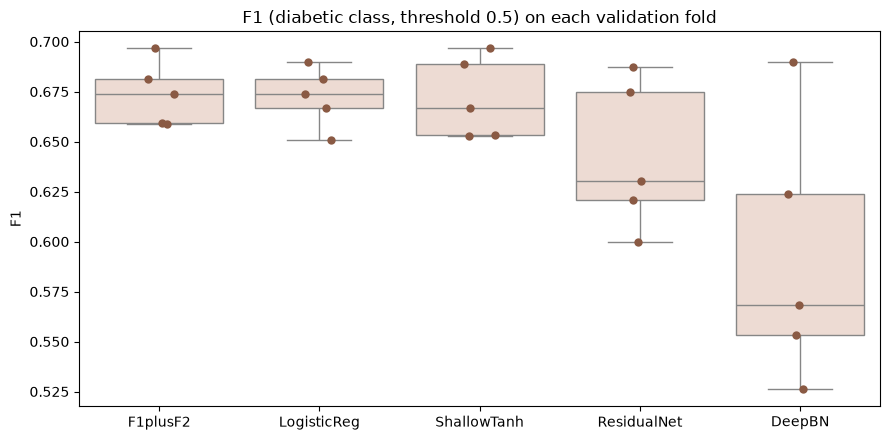

In [12]:
order = list(cv_summary.index)
plt.figure(figsize=(9, 4.5))
sns.boxplot(data=folds, x='model', y='F1', order=order, color='#F1D9CF')
sns.stripplot(data=folds, x='model', y='F1', order=order, color='#8A5A44', size=6)
plt.title('F1 (diabetic class, threshold 0.5) on each validation fold'); plt.ylabel('F1'); plt.xlabel('')
plt.tight_layout(); plt.savefig('figures/B_cv_f1.png', dpi=130); plt.show()

## 8. Retrain on the full training set, evaluate once on the test set

In [13]:
final_models, test_rows = {}, []
for name in CORES:
    model, _ = train_one(name, U.X_train, U.y_train, verbose=(name == BEST))
    final_models[name] = model
    p = predict_proba(model, U.X_test)
    m05, mt = metrics_at(U.y_test, p, 0.5), metrics_at(U.y_test, p, cv_summary.loc[name, 'threshold'])
    test_rows.append({'model': name, 'params': sum(q.numel() for q in model.core.parameters()),
                      'test_F1@0.5': m05['F1'], 'test_F1': mt['F1'], 'test_precision': mt['precision'],
                      'test_recall': mt['recall'], 'test_specificity': mt['specificity'],
                      'test_accuracy': mt['accuracy'], 'test_ROC_AUC': mt['ROC_AUC']})
results = cv_summary.join(pd.DataFrame(test_rows).set_index('model')).reset_index()
results

  F1plusF2 epoch   0 ..... 0.8365


  F1plusF2 epoch  50 ..... 0.6246


  F1plusF2 epoch 100 ..... 0.6354


,model,cv_F1@0.5_mean,cv_F1@0.5_std,cv_AUC_mean,threshold,cv_F1@threshold,params,test_F1@0.5,test_F1,test_precision,test_recall,test_specificity,test_accuracy,test_ROC_AUC
0,F1plusF2,0.673959,0.015898,0.845580,0.48,0.693966,110,0.649573,0.661157,0.597015,0.740741,0.73,0.733766,0.812778
1,LogisticReg,0.672385,0.014891,0.845329,0.59,0.684597,9,0.649573,0.592593,0.592593,0.592593,0.78,0.714286,0.812407
2,ShallowTanh,0.671656,0.020238,0.843767,0.42,0.682261,321,0.672131,0.686567,0.575000,0.851852,0.66,0.727273,0.824815
3,ResidualNet,0.642665,0.037044,0.794954,0.36,0.675052,5377,0.700855,0.704918,0.632353,0.796296,0.75,0.766234,0.816852
4,DeepBN,0.592200,0.065050,0.765994,0.20,0.637965,7105,0.601770,0.646617,0.544304,0.796296,0.64,0.694805,0.780741


F1plusF2 at threshold 0.48

              precision    recall  f1-score   support

 no diabetes     0.8391    0.7300    0.7807       100
    diabetes     0.5970    0.7407    0.6612        54

    accuracy                         0.7338       154
   macro avg     0.7180    0.7354    0.7210       154
weighted avg     0.7542    0.7338    0.7388       154



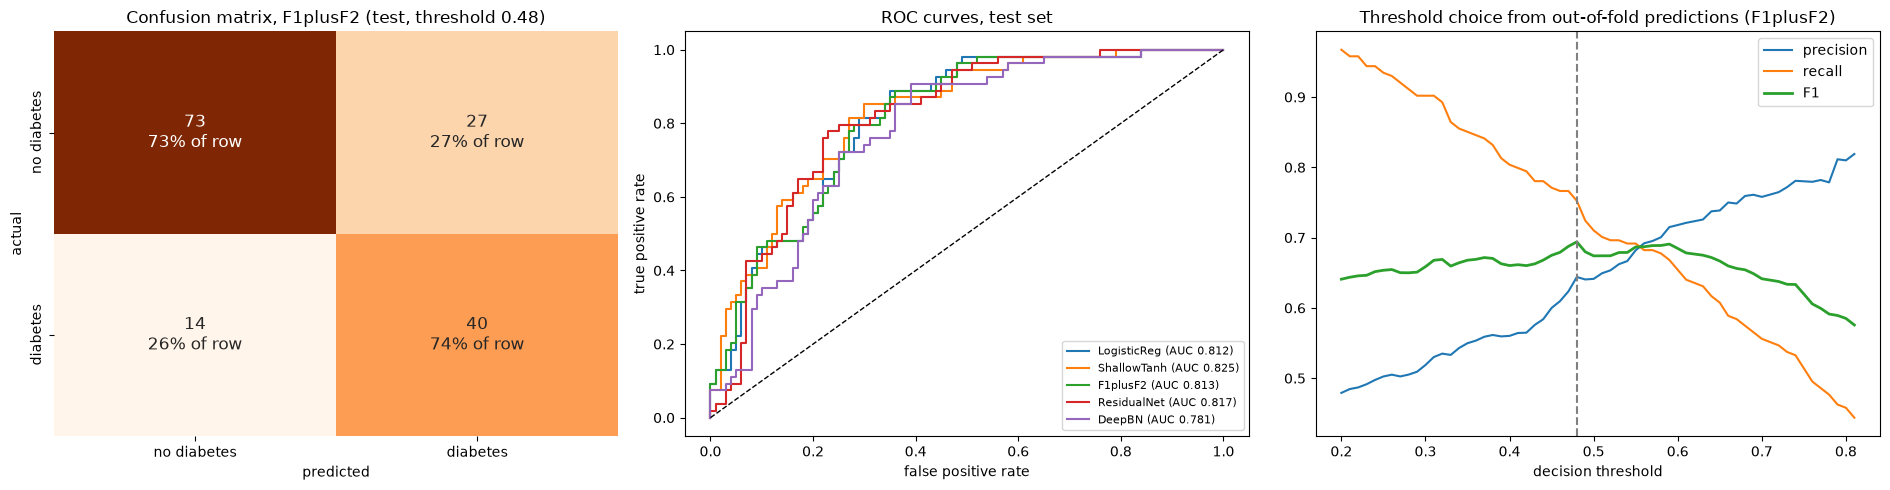

TN, FP, FN, TP = [73 27 14 40]


In [14]:
best_model = final_models[BEST]
p_best = predict_proba(best_model, U.X_test)
y_hat  = (p_best >= BEST_THRESHOLD).astype(int)
print(f'{BEST} at threshold {BEST_THRESHOLD:.2f}\n')
print(classification_report(U.y_test, y_hat, target_names=['no diabetes', 'diabetes'], digits=4))

cm = confusion_matrix(U.y_test, y_hat)
cm_row = cm / cm.sum(axis=1, keepdims=True)
cell_text = np.array([[f'{cm[i, j]}\n{cm_row[i, j]:.0%} of row' for j in range(2)] for i in range(2)])

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
sns.heatmap(cm, annot=cell_text, fmt='', cmap='Oranges', cbar=False, ax=axes[0], annot_kws={'size': 12},
            xticklabels=['no diabetes', 'diabetes'], yticklabels=['no diabetes', 'diabetes'])
axes[0].set_xlabel('predicted'); axes[0].set_ylabel('actual')
axes[0].set_title(f'Confusion matrix, {BEST} (test, threshold {BEST_THRESHOLD:.2f})')

for name, m in final_models.items():
    p = predict_proba(m, U.X_test)
    fpr, tpr, _ = roc_curve(U.y_test, p)
    axes[1].plot(fpr, tpr, label=f'{name} (AUC {roc_auc_score(U.y_test, p):.3f})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1); axes[1].set_xlabel('false positive rate'); axes[1].set_ylabel('true positive rate')
axes[1].set_title('ROC curves, test set'); axes[1].legend(fontsize=8)

prec = [precision_score(U.y_train, (oof[BEST] >= t).astype(int), zero_division=0) for t in grid]
rec  = [recall_score(U.y_train, (oof[BEST] >= t).astype(int)) for t in grid]
f1s  = [f1_score(U.y_train, (oof[BEST] >= t).astype(int)) for t in grid]
axes[2].plot(grid, prec, label='precision'); axes[2].plot(grid, rec, label='recall'); axes[2].plot(grid, f1s, label='F1', lw=2)
axes[2].axvline(BEST_THRESHOLD, color='gray', ls='--'); axes[2].set_xlabel('decision threshold')
axes[2].set_title(f'Threshold choice from out-of-fold predictions ({BEST})'); axes[2].legend()
plt.tight_layout(); plt.savefig('figures/B_results.png', dpi=130); plt.show()
print('TN, FP, FN, TP =', cm.ravel())

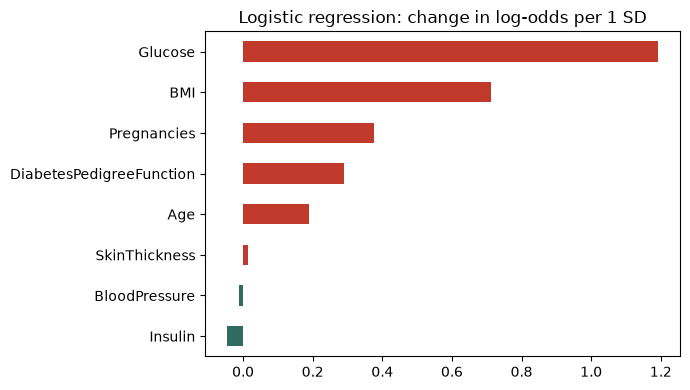

Glucose                     1.193111
BMI                         0.712379
Pregnancies                 0.375665
DiabetesPedigreeFunction    0.289542
Age                         0.188719
SkinThickness               0.014784
BloodPressure              -0.012772
Insulin                    -0.046936
dtype: float32

In [15]:
## Interpretability: logistic-regression weights on standardized inputs (log-odds per 1 SD)
w = final_models['LogisticReg'].core.linear1.weight.detach().cpu().numpy().ravel()
coef = pd.Series(w, index=FEATURES).sort_values()
coef.plot.barh(figsize=(7, 4), color=np.where(coef > 0, '#C0392B', '#2F6B5E'))
plt.title('Logistic regression: change in log-odds per 1 SD'); plt.tight_layout()
plt.savefig('figures/B_logreg_weights.png', dpi=130); plt.show()
coef.sort_values(ascending=False)

## 9. Export the selected model to ONNX

The exported graph includes zero-imputation, scaling and the sigmoid. `output1` is the probability of diabetes, with shape `[batch, 1]`.

In [16]:
class ExportWrapper(nn.Module):
    def __init__(self, m):
        super().__init__(); self.m = m
    def forward(self, x):
        return torch.sigmoid(self.m(x))

export_model = ExportWrapper(copy.deepcopy(best_model).to('cpu')).eval().float()
dummy_input  = torch.tensor(U.X_test[:1], dtype=torch.float32)
ONNX_PATH = 'ONNXmodels/diabetes_risk.onnx'

torch.onnx.export(
    export_model,
    dummy_input,
    ONNX_PATH,
    input_names=['input1'],
    output_names=['output1'],
    opset_version=15,
    do_constant_folding=True,
    dynamic_axes={'input1': {0: 'batch'}, 'output1': {0: 'batch'}},
    dynamo=False,
)
print('saved', ONNX_PATH, f'({os.path.getsize(ONNX_PATH) / 1024:.1f} KB)')

saved ONNXmodels/diabetes_risk.onnx (2.2 KB)


/tmp/ipykernel_218/1154279073.py:11: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


In [17]:
sess = rt.InferenceSession(ONNX_PATH)
print('input :', [(i.name, i.shape) for i in sess.get_inputs()])
print('output:', [(o.name, o.shape) for o in sess.get_outputs()])
onnx_prob = sess.run(['output1'], {'input1': U.X_test.astype(np.float32)})[0].ravel()
print('max |ONNX - PyTorch| =', float(np.abs(onnx_prob - p_best).max()))
print('ONNX test F1 =', f1_score(U.y_test, (onnx_prob >= BEST_THRESHOLD).astype(int)))

input : [('input1', ['batch', 8])]
output: [('output1', ['batch', 1])]
max |ONNX - PyTorch| = 1.1920928955078125e-07
ONNX test F1 = 0.6611570247933884


In [18]:
pos, neg = np.where(U.y_test == 1)[0], np.where(U.y_test == 0)[0]
idx = [int(pos[0]), int(neg[0]), int(pos[1])]
samples = [{'inputs': dict(zip(FEATURES, [round(float(v), 4) for v in U.X_test[i]])),
            'actual': int(U.y_test[i]), 'onnx_prob': float(onnx_prob[i])} for i in idx]
for s in samples:
    print(s)

summary_out = {'best_model': BEST, 'threshold': BEST_THRESHOLD, 'features': FEATURES,
               'zero_means_missing': ZERO_MEANS_MISSING,
               'medians': best_model.medians.cpu().numpy().ravel().tolist(),
               'cv_and_test': results.to_dict(orient='records'), 'cv_folds': folds.to_dict(orient='records'),
               'confusion_matrix': cm.tolist(), 'logreg_weights': coef.to_dict(),
               'n_train': int(len(U.y_train)), 'n_test': int(len(U.y_test)), 'samples': samples}
with open('ONNXmodels/classification_results.json', 'w') as f:
    json.dump(summary_out, f, indent=2, default=float)
print('saved ONNXmodels/classification_results.json')

{'inputs': {'Pregnancies': 7.0, 'Glucose': 114.0, 'BloodPressure': 64.0, 'SkinThickness': 0.0, 'Insulin': 0.0, 'BMI': 27.4, 'DiabetesPedigreeFunction': 0.732, 'Age': 34.0}, 'actual': 1, 'onnx_prob': 0.3952011466026306}
{'inputs': {'Pregnancies': 7.0, 'Glucose': 159.0, 'BloodPressure': 64.0, 'SkinThickness': 0.0, 'Insulin': 0.0, 'BMI': 27.4, 'DiabetesPedigreeFunction': 0.294, 'Age': 40.0}, 'actual': 0, 'onnx_prob': 0.7330938577651978}
{'inputs': {'Pregnancies': 8.0, 'Glucose': 105.0, 'BloodPressure': 100.0, 'SkinThickness': 36.0, 'Insulin': 0.0, 'BMI': 43.3, 'DiabetesPedigreeFunction': 0.239, 'Age': 45.0}, 'actual': 1, 'onnx_prob': 0.6648063063621521}
saved ONNXmodels/classification_results.json
